In [21]:
import torch

words = open('names.txt', 'r').read().splitlines()
len(words)

32033

In [33]:
min(len(w) for w in words[:10])

3

In [35]:
max(len(w) for w in words)


15

In [43]:
b = {}
for w in words:
  chs = ['<S>'] + list(w) + ['<E>']
  print(chs, chs[1:])
  for ch1, ch2 in zip(chs, chs[1:]):
    bigram = (ch1, ch2)
    b[bigram] = b.get(bigram, 0) + 1

['<S>', 'e', 'm', 'm', 'a', '<E>'] ['e', 'm', 'm', 'a', '<E>']
['<S>', 'o', 'l', 'i', 'v', 'i', 'a', '<E>'] ['o', 'l', 'i', 'v', 'i', 'a', '<E>']
['<S>', 'a', 'v', 'a', '<E>'] ['a', 'v', 'a', '<E>']
['<S>', 'i', 's', 'a', 'b', 'e', 'l', 'l', 'a', '<E>'] ['i', 's', 'a', 'b', 'e', 'l', 'l', 'a', '<E>']
['<S>', 's', 'o', 'p', 'h', 'i', 'a', '<E>'] ['s', 'o', 'p', 'h', 'i', 'a', '<E>']
['<S>', 'c', 'h', 'a', 'r', 'l', 'o', 't', 't', 'e', '<E>'] ['c', 'h', 'a', 'r', 'l', 'o', 't', 't', 'e', '<E>']
['<S>', 'm', 'i', 'a', '<E>'] ['m', 'i', 'a', '<E>']
['<S>', 'a', 'm', 'e', 'l', 'i', 'a', '<E>'] ['a', 'm', 'e', 'l', 'i', 'a', '<E>']
['<S>', 'h', 'a', 'r', 'p', 'e', 'r', '<E>'] ['h', 'a', 'r', 'p', 'e', 'r', '<E>']
['<S>', 'e', 'v', 'e', 'l', 'y', 'n', '<E>'] ['e', 'v', 'e', 'l', 'y', 'n', '<E>']
['<S>', 'a', 'b', 'i', 'g', 'a', 'i', 'l', '<E>'] ['a', 'b', 'i', 'g', 'a', 'i', 'l', '<E>']
['<S>', 'e', 'm', 'i', 'l', 'y', '<E>'] ['e', 'm', 'i', 'l', 'y', '<E>']
['<S>', 'e', 'l', 'i', 'z', 'a', '

In [38]:
sorted(b.items(), key = lambda kv: -kv[1])  # 把所有 bigram 按照出现次数从大到小排序

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [44]:
import torch


In [48]:
N = torch.zeros((27, 27), dtype = torch.int32)
print(N.size())

torch.Size([27, 27])


In [54]:
print(''.join(words))
chars = sorted(list(set(''.join(words))))
print(chars)

stoi = {s:i+1 for i,s in enumerate(chars)}
print(stoi)
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

...
['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [58]:
for w in words:
  chs = ['.'] + list(w) + ['.']
  print(chs)
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1   # 建立一个数组，统计每一种二元对出现的次数

['.', 'e', 'm', 'm', 'a', '.']
['.', 'o', 'l', 'i', 'v', 'i', 'a', '.']
['.', 'a', 'v', 'a', '.']
['.', 'i', 's', 'a', 'b', 'e', 'l', 'l', 'a', '.']
['.', 's', 'o', 'p', 'h', 'i', 'a', '.']
['.', 'c', 'h', 'a', 'r', 'l', 'o', 't', 't', 'e', '.']
['.', 'm', 'i', 'a', '.']
['.', 'a', 'm', 'e', 'l', 'i', 'a', '.']
['.', 'h', 'a', 'r', 'p', 'e', 'r', '.']
['.', 'e', 'v', 'e', 'l', 'y', 'n', '.']
['.', 'a', 'b', 'i', 'g', 'a', 'i', 'l', '.']
['.', 'e', 'm', 'i', 'l', 'y', '.']
['.', 'e', 'l', 'i', 'z', 'a', 'b', 'e', 't', 'h', '.']
['.', 'm', 'i', 'l', 'a', '.']
['.', 'e', 'l', 'l', 'a', '.']
['.', 'a', 'v', 'e', 'r', 'y', '.']
['.', 's', 'o', 'f', 'i', 'a', '.']
['.', 'c', 'a', 'm', 'i', 'l', 'a', '.']
['.', 'a', 'r', 'i', 'a', '.']
['.', 's', 'c', 'a', 'r', 'l', 'e', 't', 't', '.']
['.', 'v', 'i', 'c', 't', 'o', 'r', 'i', 'a', '.']
['.', 'm', 'a', 'd', 'i', 's', 'o', 'n', '.']
['.', 'l', 'u', 'n', 'a', '.']
['.', 'g', 'r', 'a', 'c', 'e', '.']
['.', 'c', 'h', 'l', 'o', 'e', '.']
['.', 'p',

(-0.5, 26.5, 26.5, -0.5)

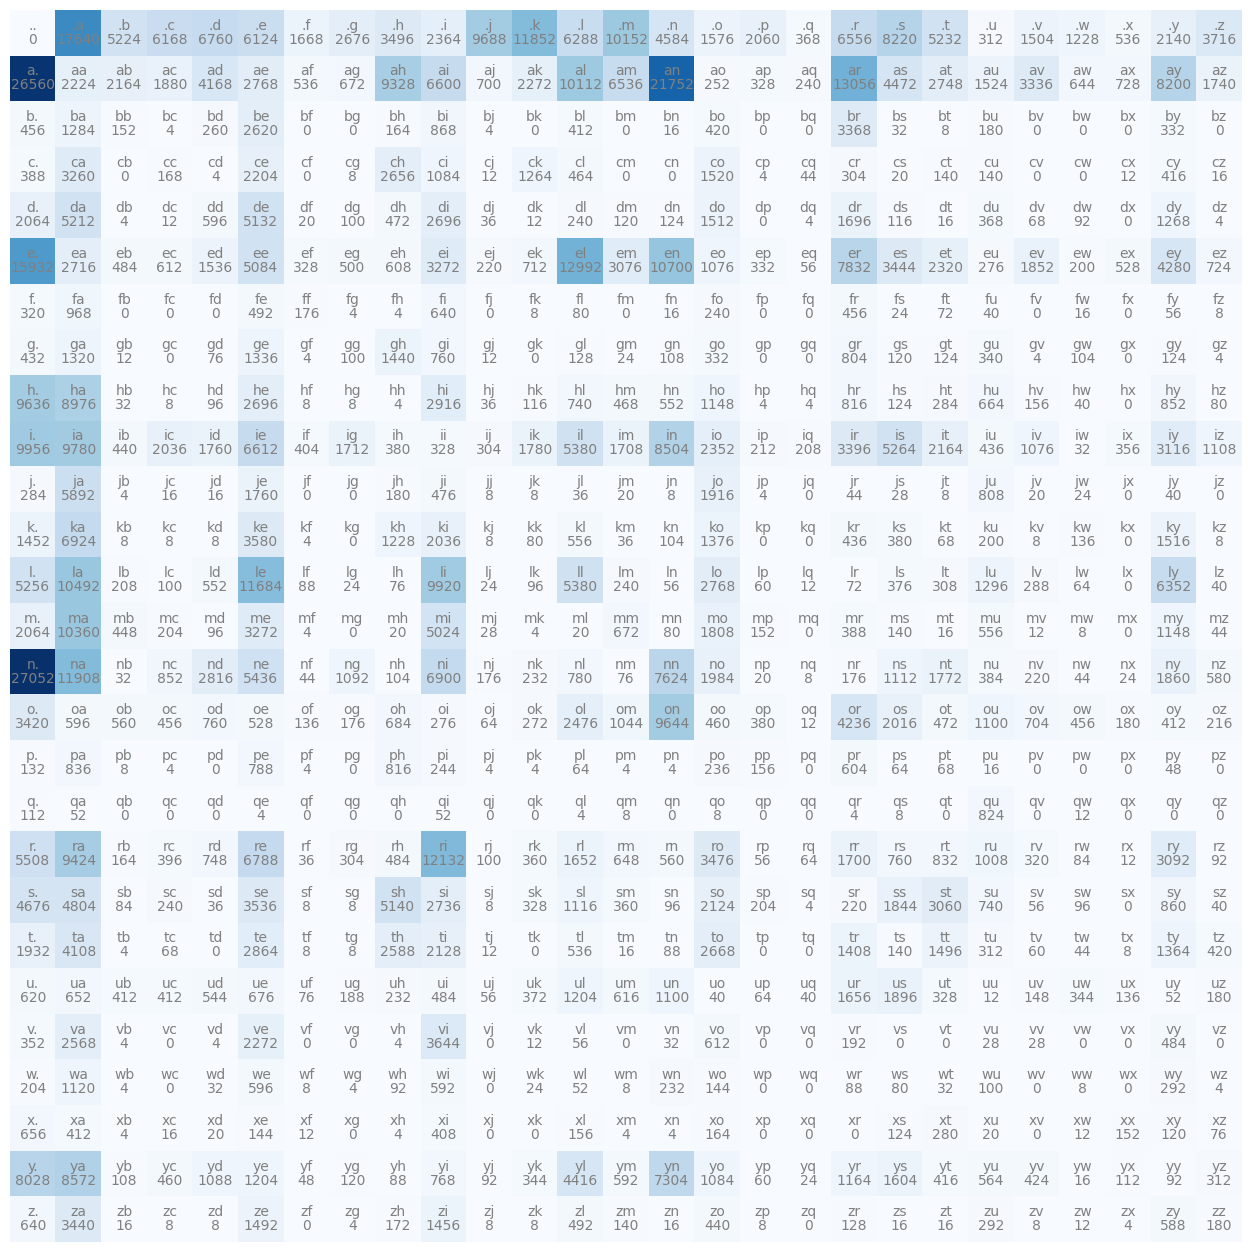

In [72]:
import matplotlib.pyplot as plt
%matplotlib inline

# 可视化相邻字符对出现的次数
plt.figure(figsize=(16, 16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off')

In [83]:
p = N[0].float()
p = p / p.sum()
p
print(p)  # . + char 意味着首字符的概率
print(p.sum())

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])
tensor(1.)


In [91]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=10, replacement=True, generator=g)
#ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
print(ix)
#itos[ix]

tensor([13, 19, 14,  1,  1, 20, 20,  1, 13, 13])


In [92]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
print(p)
p = p / p.sum()
p

tensor([0.7081, 0.3542, 0.1054])


tensor([0.6064, 0.3033, 0.0903])

In [93]:
torch.multinomial(p, num_samples=10, replacement=True, generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0])

In [94]:
p.shape

torch.Size([3])

In [96]:
print(N)

tensor([[    0, 17640,  5224,  6168,  6760,  6124,  1668,  2676,  3496,  2364,
          9688, 11852,  6288, 10152,  4584,  1576,  2060,   368,  6556,  8220,
          5232,   312,  1504,  1228,   536,  2140,  3716],
        [26560,  2224,  2164,  1880,  4168,  2768,   536,   672,  9328,  6600,
           700,  2272, 10112,  6536, 21752,   252,   328,   240, 13056,  4472,
          2748,  1524,  3336,   644,   728,  8200,  1740],
        [  456,  1284,   152,     4,   260,  2620,     0,     0,   164,   868,
             4,     0,   412,     0,    16,   420,     0,     0,  3368,    32,
             8,   180,     0,     0,     0,   332,     0],
        [  388,  3260,     0,   168,     4,  2204,     0,     8,  2656,  1084,
            12,  1264,   464,     0,     0,  1520,     4,    44,   304,    20,
           140,   140,     0,     0,    12,   416,    16],
        [ 2064,  5212,     4,    12,   596,  5132,    20,   100,   472,  2696,
            36,    12,   240,   120,   124,  1512,   

In [100]:
P = N[0].float()
print(P)

tensor([    0., 17640.,  5224.,  6168.,  6760.,  6124.,  1668.,  2676.,  3496.,
         2364.,  9688., 11852.,  6288., 10152.,  4584.,  1576.,  2060.,   368.,
         6556.,  8220.,  5232.,   312.,  1504.,  1228.,   536.,  2140.,  3716.])
tensor([[    1, 17641,  5225,  6169,  6761,  6125,  1669,  2677,  3497,  2365,
          9689, 11853,  6289, 10153,  4585,  1577,  2061,   369,  6557,  8221,
          5233,   313,  1505,  1229,   537,  2141,  3717],
        [26561,  2225,  2165,  1881,  4169,  2769,   537,   673,  9329,  6601,
           701,  2273, 10113,  6537, 21753,   253,   329,   241, 13057,  4473,
          2749,  1525,  3337,   645,   729,  8201,  1741],
        [  457,  1285,   153,     5,   261,  2621,     1,     1,   165,   869,
             5,     1,   413,     1,    17,   421,     1,     1,  3369,    33,
             9,   181,     1,     1,     1,   333,     1],
        [  389,  3261,     1,   169,     5,  2205,     1,     9,  2657,  1085,
            13,  1265,   465,

In [106]:
P = (N + 1).float()
P = P / P.sum(1, keepdim=True)
print(P)

tensor([[7.8028e-06, 1.3765e-01, 4.0770e-02, 4.8136e-02, 5.2755e-02, 4.7792e-02,
         1.3023e-02, 2.0888e-02, 2.7286e-02, 1.8454e-02, 7.5601e-02, 9.2487e-02,
         4.9072e-02, 7.9222e-02, 3.5776e-02, 1.2305e-02, 1.6082e-02, 2.8792e-03,
         5.1163e-02, 6.4147e-02, 4.0832e-02, 2.4423e-03, 1.1743e-02, 9.5897e-03,
         4.1901e-03, 1.6706e-02, 2.9003e-02],
        [1.9593e-01, 1.6413e-02, 1.5970e-02, 1.3875e-02, 3.0752e-02, 2.0425e-02,
         3.9611e-03, 4.9643e-03, 6.8815e-02, 4.8692e-02, 5.1709e-03, 1.6767e-02,
         7.4598e-02, 4.8220e-02, 1.6046e-01, 1.8662e-03, 2.4268e-03, 1.7777e-03,
         9.6314e-02, 3.2995e-02, 2.0278e-02, 1.1249e-02, 2.4615e-02, 4.7578e-03,
         5.3774e-03, 6.0494e-02, 1.2842e-02],
        [4.3085e-02, 1.2115e-01, 1.4424e-02, 4.7139e-04, 2.4606e-02, 2.4710e-01,
         9.4277e-05, 9.4277e-05, 1.5556e-02, 8.1927e-02, 4.7139e-04, 9.4277e-05,
         3.8937e-02, 9.4277e-05, 1.6027e-03, 3.9691e-02, 9.4277e-05, 9.4277e-05,
         3.1762e-

In [111]:
P[0].sum()
print(P[0].sum())
print(P[1].sum())
print(P[2].sum())
print(P[26].sum())

tensor(1.)
tensor(1.0000)
tensor(1.)
tensor(1.0000)


In [120]:
g = torch.Generator().manual_seed(2147483647+2)
""" 根据预先统计的概率来随机采样，生成五个名字 """
for i in range(10):
  
  out = []
  ix = 0
  while True:
    p = P[ix]
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

# 这样生成的名字会符合训练数据中字符对的统计规律，所以说 bigram 是用人工统计的方式来学习，相当于模型参数
# 是人工统计的，并不是让模型自己学习

lyli.
ndaiahla.
ara.
ra.
a.
siren.
kamastitriti.
e.
ssde.
kasia.
